In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown


# 01 — OCR dataset exploration

**Research question:** Dữ liệu nào phù hợp để khảo sát OCR, và dữ liệu nào đủ để đo độ chính xác InBody?

Module 01 ưu tiên Dataset → Document AI trước tích hợp ứng dụng. Seed 42; không tải phiếu thật hoặc dữ liệu bên thứ ba trong notebook này.

In [2]:
sources = json.loads((ROOT / "data/manifests/document_ai_sources.json").read_text(encoding="utf-8"))
rows = ["| Source | Role | Availability |", "|---|---|---|"]
for item in sources["sources"]:
    rows.append(f"| {item['id']} | {item['role']} | {item['download_status']} |")
display(Markdown("\n".join(rows)))

| Source | Role | Availability |
|---|---|---|
| funsd | Generic noisy form OCR and field-relation exploration, not InBody labels | not_downloaded |
| sroie | Receipt OCR/KIE baseline exploration, not InBody labels | not_downloaded |
| doclaynet | Layout bounding boxes; not a specialized InBody benchmark | not_downloaded |
| inbody_sample_sheets | Candidate reference for manual layout exploration | not_downloaded |
| inbody_real_consented | Required independent real-world InBody benchmark | not_available |
| inbody_synthetic_v1 | Original layout, deterministic pipeline smoke tests only | generated_locally |

## Baseline và experiment config

Dùng 16 ảnh tự sinh từ layout riêng, không có người thật/logo/mẫu phiếu của hãng. 8 dev + 8 smoke_test; nhãn và transcript sinh cùng lúc. FUNSD/SROIE hỗ trợ khám phá form/receipt, không cung cấp nhãn InBody chuyên biệt. Nguồn và trạng thái quyền sử dụng ghi trong manifest.

In [3]:
from scripts.prepare_inbody_synthetic import prepare
manifest_path = ROOT / "data/manifests/inbody_synthetic_v1.json"
if not manifest_path.exists():
    prepare()
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
from collections import Counter
print("Dataset:", manifest["dataset_id"], "Seed:", manifest["seed"])
print("Split counts:", dict(Counter(s["split"] for s in manifest["samples"])))
print("Real documents:", manifest["real_documents"])
groups = {}
for sample in manifest["samples"]:
    assert groups.setdefault(sample["subject_id"], sample["split"]) == sample["split"]
print("Subject split check: passed")

Dataset: inbody-synthetic-smoke-v1 Seed: 42
Split counts: {'dev': 8, 'smoke_test': 8}
Real documents: 0
Subject split check: passed


synthetic-000 (1200, 1000) dev


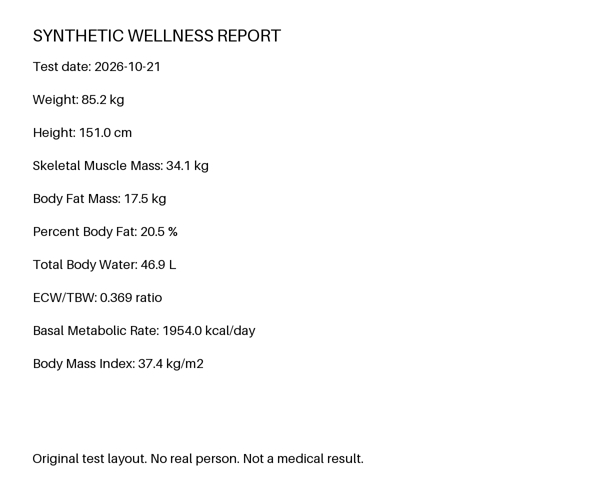

synthetic-001 (1200, 1000) dev


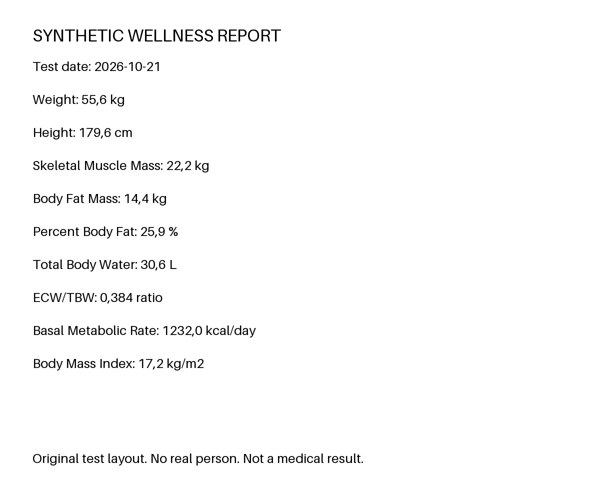

In [4]:
from PIL import Image
import hashlib
for sample in manifest["samples"][:2]:
    path = ROOT / sample["image"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == sample["sha256"]
    image = Image.open(path)
    print(sample["document_id"], image.size, sample["split"])
    display(image.resize((600, 500)))

## Metrics / error analysis / conclusion

Ở bước khảo sát chỉ báo số tài liệu, mức đầy đủ nhãn, đơn vị và leakage; chưa báo OCR accuracy. Bộ giả lập có layout sạch, ngôn ngữ tiếng Anh, cùng renderer nên không đại diện ảnh chụp điện thoại/phiếu thật. Cần thu thập phiếu được cấp quyền, gán nhãn độc lập theo guideline rồi khóa test theo người/phiếu gốc.

In [5]:
from src.document_ai.schema import FIELDS
missing = Counter()
for sample in manifest["samples"]:
    label = json.loads((ROOT / sample["annotation"]).read_text(encoding="utf-8"))
    missing.update(key for key in FIELDS if label["values"][key] is None)
print("Missing labels:", dict(missing))
display(Markdown("Annotation guideline: `docs/module_01/annotation_guideline.md`"))

Missing labels: {'total_body_water_l': 2}


Annotation guideline: `docs/module_01/annotation_guideline.md`